 # Unsupervised Machine Learning Capstone:US Arrests (1973)
 This note explores arrest rates across the 50 US state using principal compoonent analysis (PCA) and clustering.

 The dataset contains 1973 arrest rates per 100,000 resident for Murder,Assault, and Rape, as well as percentage of the population living in urban areas ('UrbanPop').
  

In [1]:
#Data handling

import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


In [2]:



def load_data(file_path):
    """Load the US Arrests CSV and use state names as the index."""
    data = pd.read_csv(file_path)

   # The first column holds state names, even though it is labelled 'City'
    data = data.rename(columns={'City': 'State'}).set_index('State')
    return data

arrests_df = load_data('UsArrests.csv')
arrests_df.head()


,Murder,Assault,UrbanPop,Rape
State,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [19]:
def summarise_data(data):
    """Print the shape, data types and missing values of a DataFrame."""
    print(f"Rows: {data.shape[0]}, Columns: {data.shape[1]}\n")
    print("Data types:")
    print(data.dtypes)
    print("Missing values per column:")
    print(data.isna().sum())

    
summarise_data(arrests_df)


Rows: 50, Columns: 4

Data types:
Murder      float64
Assault       int64
UrbanPop      int64
Rape        float64
dtype: object
Missing values per column:
Murder      0
Assault     0
UrbanPop    0
Rape        0
dtype: int64


In [20]:
arrests_df.describe().round(2)

,Murder,Assault,UrbanPop,Rape
count,50.00,50.00,50.00,50.00
mean,7.79,170.76,65.54,21.23
std,4.36,83.34,14.47,9.37
min,0.80,45.00,32.00,7.30
25%,4.08,109.00,54.50,15.08
50%,7.25,159.00,66.00,20.10
75%,11.25,249.00,77.75,26.18
max,17.40,337.00,91.00,46.00


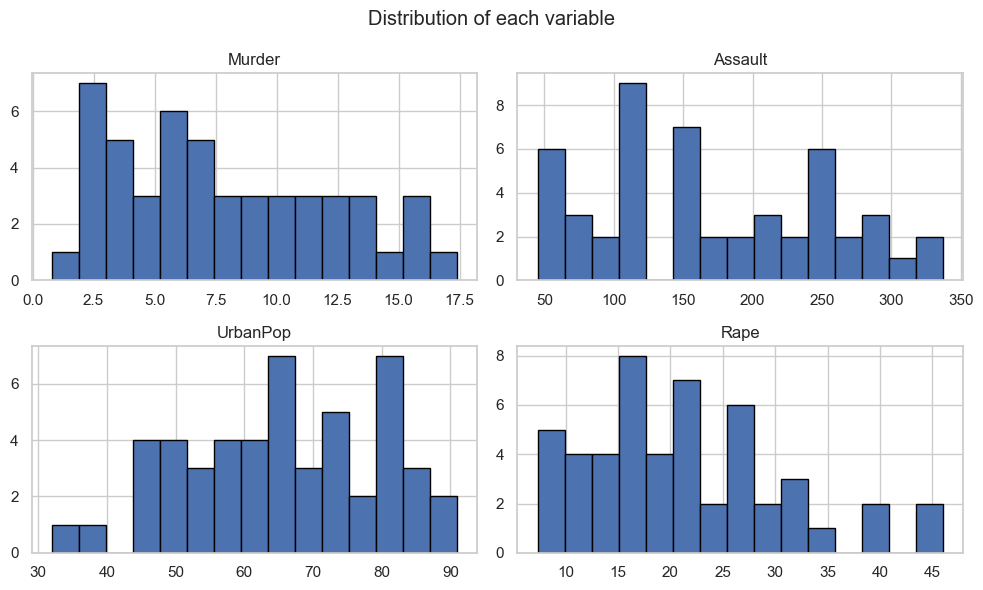

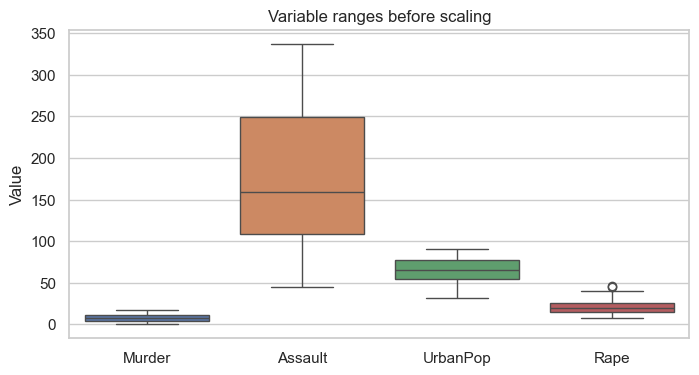

In [ ]:
def plot_distributions(data):
    """Plot histogram of each variable and a boxplot comparing their scales."""
    data.hist(bins=15, figsize=(10, 6), edgecolor='black')
    plt.suptitle('Distribution of each variable')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=data)
    plt.title('Variable ranges before scaling')
    plt.ylabel('Value')
    plt.show()

plot_distributions(arrests_df)

In [22]:
def standardise_data(data):
    """Scale each column to mean 0 and standard deviation 1."""
    scaler = StandardScaler()
    scaled_values = scaler.fit_transform(data)
    return pd.DataFrame(scaled_values, columns=data.columns, index=data.index)

scaled_df= standardise_data(arrests_df)
scaled_df.describe().round(2)


,Murder,Assault,UrbanPop,Rape
count,50.00,50.00,50.00,50.00
mean,-0.00,0.00,-0.00,0.00
std,1.01,1.01,1.01,1.01
min,-1.62,-1.52,-2.34,-1.50
25%,-0.86,-0.75,-0.77,-0.66
50%,-0.12,-0.14,0.03,-0.12
75%,0.80,0.95,0.85,0.53
max,2.23,2.02,1.78,2.67


### Data exploration and preprocessing

- 50 rows (one per state), 4 numeric variables, no missing values, so no imputation is needed.
- The first column is labelled 'City' but holds state names. Renames to 'State' and set as the index so it is not treated as a feature. 
- Units differ : crime rates are per 100,000 residents, UrbanPop is a percentage.
- Assault has a far larger scale (std = 83) than Murder (std = 4.4). PCA maximises variance, so unscaled, Assault would dominate PC1.
- The data was therefore standardised to mean 0 and standard deviation 1.
- Rape is slightly right-skewed (Nevada, Alaska), but these are genuine values, so no outliers were removed.

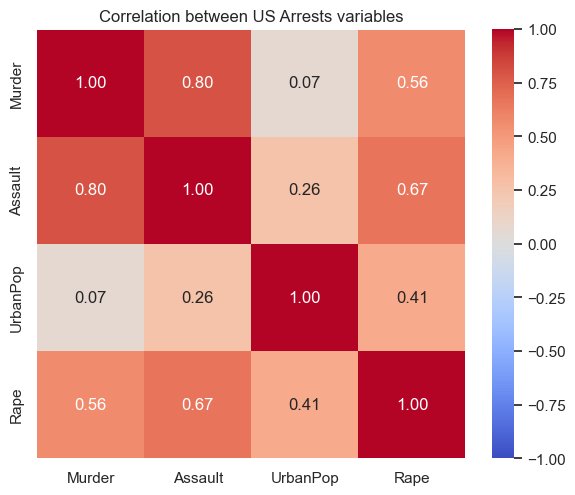

In [37]:
def plot_correlation_heatmap(data, title):
    """Calculate and plot the pairwise correlation matrix for DataFrame"""
    correlation= data.corr()

    plt.figure(figsize=(6, 5))
    sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm',
                vmin=-1, vmax=1, square=True)
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return correlation

feature_corr = plot_correlation_heatmap(
    arrests_df, 'Correlation between US Arrests variables'
)

In [38]:
def rank_correlation(correlation):
    """Return each unique variable pair ranked by absolute correlation."""
    pairs = correlation.unstack()
    # Remove self-correlation and the duplicated mirror half of the matrix
    pairs = pairs[pairs.index.get_level_values(0)< pairs.index.get_level_values(1)]
    ranked = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
    return ranked.round(2).rename('Correlation').to_frame()

rank_correlation(feature_corr)

Correlation
Assault Murder           0.80
        Rape             0.67
Murder  Rape             0.56
Rape    UrbanPop         0.41
Assault UrbanPop         0.26
Murder  UrbanPop         0.07

### Correlation analysis
- The three crime variables are all positively correlated, most strongly Murder and Assault (0.80), followed by Assault and Rape (0.67) and Murder and Rape (0.56). States with high rates of one violent crime tend to have high rates of the others, so these variables carry overlapping information.
- UrbanPop behaves differently. It has a moderate correlation with Rape (0.41) but almost none with Murder (0.07). Urbanisation is therefore largely independent of the murder rate.
- This pattern suggests the data has roughly two underlying dimensions: overall violent crime level, and urbanisation. That redundacy is exactly what PCA exploits, and it suggests two components should capture most of the variance.

In [25]:

def fit_pca(data, n_components=None):
    """Fit PCA to scaled data and return the model with the transformed values."""
    pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
    components = pca.fit_transform(data)
    component_names = [f'PC{i + 1}' for i in range(components.shape[1])]
    components_df = pd.DataFrame(components, columns=component_names,
                                 index=data.index)
    return pca, components_df


pca_model, pca_df = fit_pca(scaled_df)

variance_summary = pd.DataFrame({
    'Explained variance (%)': pca_model.explained_variance_ratio_ * 100,
    'Cumulative (%)': np.cumsum(pca_model.explained_variance_ratio_) * 100
}, index=pca_df.columns).round(2)

variance_summary


,Explained variance (%),Cumulative (%)
PC1,62.01,62.01
PC2,24.74,86.75
PC3,8.91,95.66
PC4,4.34,100.00


In [26]:
loadings =pd.DataFrame(pca_model.components_.T,
                       columns=pca_df.columns,
                      index=scaled_df.columns)
loadings.round(2)

,PC1,PC2,PC3,PC4
Murder,0.54,-0.42,-0.34,-0.65
Assault,0.58,-0.19,-0.27,0.74
UrbanPop,0.28,0.87,-0.38,-0.13
Rape,0.54,0.17,0.82,-0.09


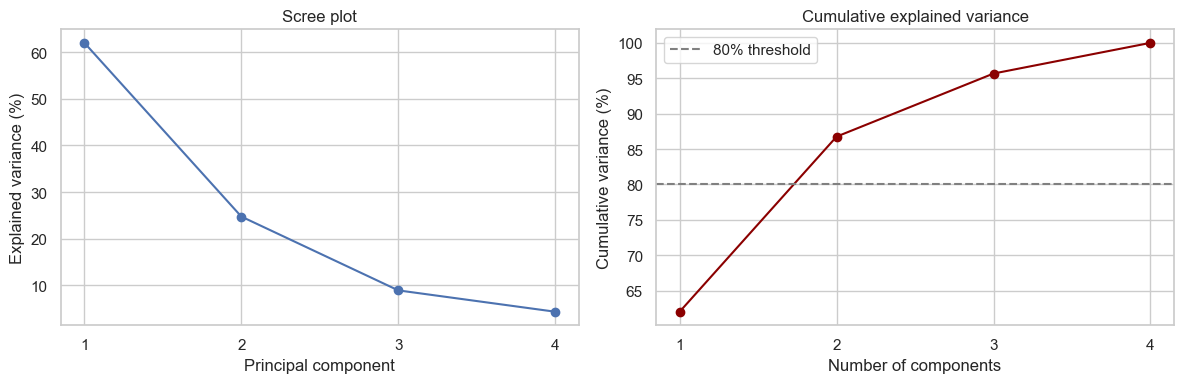

In [27]:
def plot_variance(pca): 
    """Plot the scree curve and the cumulative explained variance."""
    n_components = len(pca.explained_variance_ratio_)
    component_numbers = range(1, n_components + 1)
    cumulative = np.cumsum(pca.explained_variance_ratio_) * 100

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(component_numbers, pca.explained_variance_ratio_ * 100, marker='o')
    axes[0].set_title('Scree plot')
    axes[0].set_xlabel('Principal component')
    axes[0].set_ylabel('Explained variance (%)')
    axes[0].set_xticks(component_numbers)

    axes[1].plot(component_numbers, cumulative, marker='o', color='darkred')
    axes[1].axhline(80, linestyle='--', color='grey', label='80% threshold')
    axes[1].set_title('Cumulative explained variance')
    axes[1].set_xlabel('Number of components')
    axes[1].set_ylabel('Cumulative variance (%)')
    axes[1].set_xticks(component_numbers)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


plot_variance(pca_model)


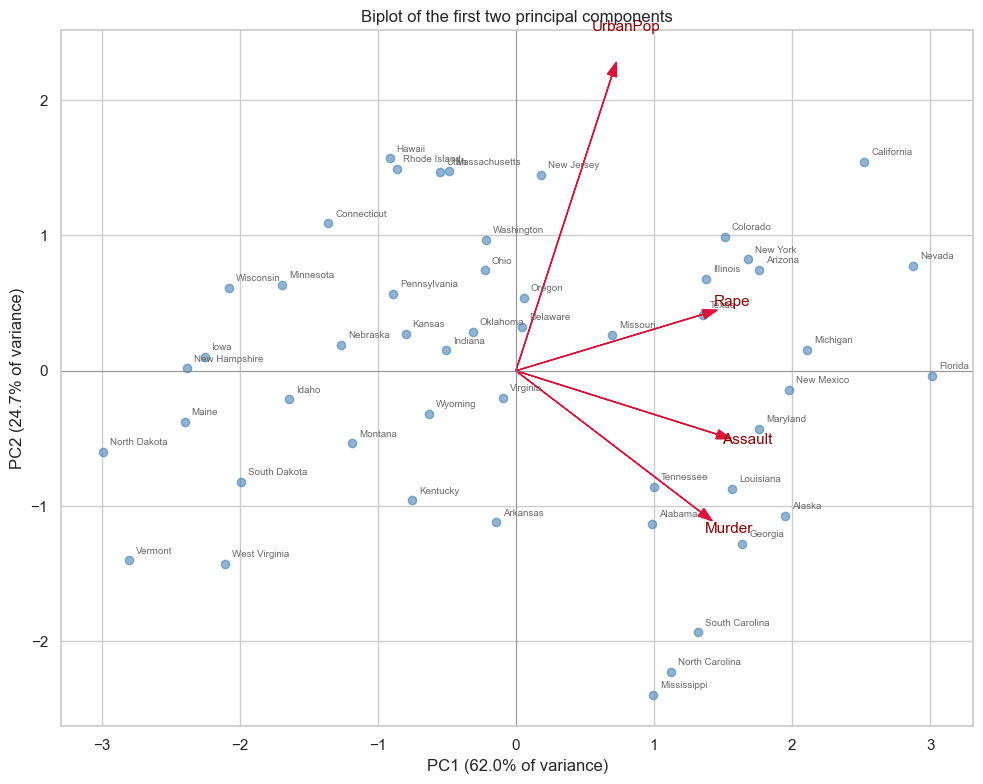

In [28]:
def plot_biplot(components_df, pca, feature_names, arrow_scale=2.5):
    """Plot PC1 vs PC2 with state labels and feature loading arrows."""
    plt.figure(figsize=(10, 8))
    plt.scatter(components_df['PC1'], components_df['PC2'],
                alpha=0.6, color='steelblue')

    # Label each state so individual points can be interpreted
    for state in components_df.index:
        plt.text(components_df.loc[state, 'PC1'] + 0.05,
                 components_df.loc[state, 'PC2'] + 0.05,
                 state, fontsize=7, color='dimgrey')

    # Draw one arrow per original feature
    for i, feature in enumerate(feature_names):
        dx = pca.components_[0, i] * arrow_scale
        dy = pca.components_[1, i] * arrow_scale
        plt.arrow(0, 0, dx, dy, color='crimson', head_width=0.07)
        plt.text(dx * 1.15, dy * 1.15, feature, color='darkred',
                 fontsize=11, ha='center')

    plt.axhline(0, color='grey', linewidth=0.5)
    plt.axvline(0, color='grey', linewidth=0.5)
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)')
    plt.title('Biplot of the first two principal components')
    plt.tight_layout()
    plt.show()


plot_biplot(pca_df, pca_model, scaled_df.columns)


### PCA result and biplot interpretation
- **PC1 (62.0%)**: loads positively on Murder, Assault and Rape, so it measures overall violent crime. High on the right (Florida, Nevada, California), low on the left (North Dakota, Vermont, Maine).
- **PC2 (24.7%)**: dominated by UrbanPop, whose arrow points up while the crime arrows point right. It separates urbanisation from crime. Urban states sit at the top (Hawaii, Rhode Island); rural ones at the bottom (Mississippi, the Carolinas).
- The three crime arrows cluster together, confirming their strong mutual correlations. Murder tilts slightly down, matching its near-zero correlation with UrbanPop.
- Contrasts: California is high on both; Mississippi has high crime but low urbanisation; Hawaii is urban but low crime.

### Choosing the number of components
Two components were retained:
- PC1 and PC2 explain 86.8% of the variance, above the 80% threshold.
- The scree plot elbows after PC2; PC3 and PC4 add only 8.9% and 4.3%.
- Only PC1 and PC2 have eigenvalues above 1 (Kaiser criterion).
- Two components also allow clusters to be plotted directly in 2D

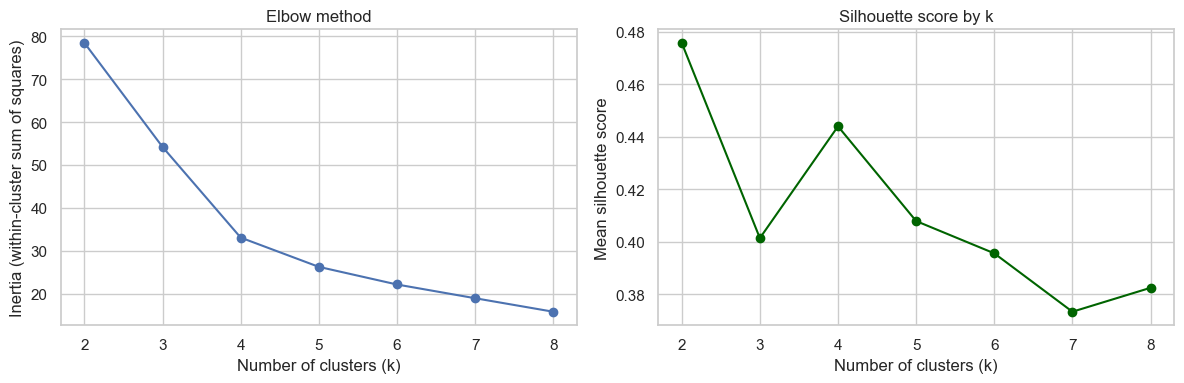

,k,Inertia,Silhouette
0,2,78.46,0.476
1,3,54.19,0.401
2,4,33.05,0.444
3,5,26.22,0.408
4,6,22.11,0.396
5,7,18.91,0.373
6,8,15.76,0.382


In [29]:
def plot_kmeans_diagnostics(data, k_range=range(2, 9)):
    """Plot the elbow curve and silhouette scores to help choose k."""
    inertias = []
    silhouettes = []

    for k in k_range:
        model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
        labels = model.fit_predict(data)
        inertias.append(model.inertia_)
        silhouettes.append(silhouette_score(data, labels))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(list(k_range), inertias, marker='o')
    axes[0].set_title('Elbow method')
    axes[0].set_xlabel('Number of clusters (k)')
    axes[0].set_ylabel('Inertia (within-cluster sum of squares)')

    axes[1].plot(list(k_range), silhouettes, marker='o', color='darkgreen')
    axes[1].set_title('Silhouette score by k')
    axes[1].set_xlabel('Number of clusters (k)')
    axes[1].set_ylabel('Mean silhouette score')

    plt.tight_layout()
    plt.show()

    return pd.DataFrame({'k': list(k_range),
                         'Inertia': np.round(inertias, 2),
                         'Silhouette': np.round(silhouettes, 3)})


# Cluster on the first two components, which retain 86.8% of the variance
pca_2d = pca_df[['PC1', 'PC2']]
plot_kmeans_diagnostics(pca_2d)


### Choosing the number of clusters
k = 4 was selected. k = 2 has the highest silhouette score (0.476) but only separates high- from low-crime states, which PC1 already shows. The elbow curve flattens around k = 4, whose silhouette (0.444) is close behind, and four clusters use both components, distinguishing urban from rural states within each crime level.

In [30]:
K_CLUSTERS = 4

kmeans = KMeans(n_clusters=K_CLUSTERS, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(pca_2d)

results_df = pca_2d.copy()
results_df['KMeans'] = kmeans_labels

print(f"K-means silhouette score: {silhouette_score(pca_2d, kmeans_labels):.3f}\n")
print("States per cluster:")
print(results_df['KMeans'].value_counts().sort_index())


K-means silhouette score: 0.444

States per cluster:
KMeans
0     9
1    12
2    18
3    11
Name: count, dtype: int64


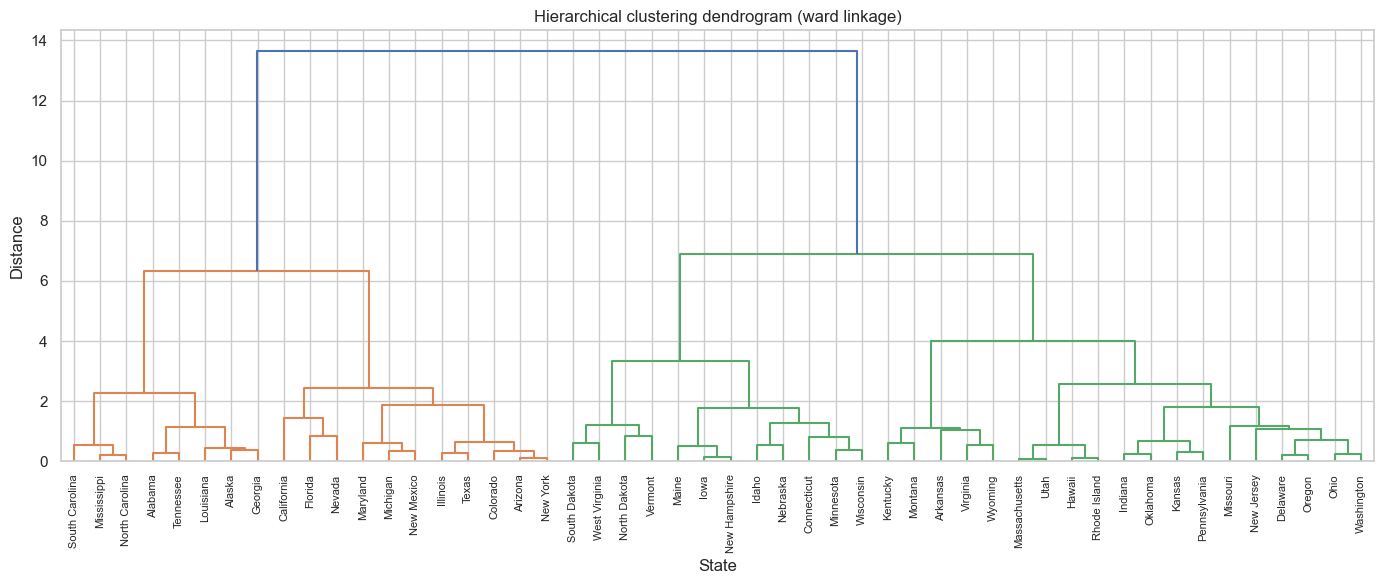

Hierarchical silhouette score: 0.413

States per cluster:
Hierarchical
1     8
2    11
3    12
4    19
Name: count, dtype: int64


In [31]:
def plot_dendrogram(data, method='ward'):
    """Plot a labelled dendrogram for the chosen linkage method."""
    linkage_matrix = linkage(data, method=method)

    plt.figure(figsize=(14, 6))
    dendrogram(linkage_matrix, labels=data.index.tolist(), leaf_font_size=8)
    plt.title(f'Hierarchical clustering dendrogram ({method} linkage)')
    plt.xlabel('State')
    plt.ylabel('Distance')
    plt.tight_layout()
    plt.show()

    return linkage_matrix


ward_linkage = plot_dendrogram(pca_2d)
hierarchical_labels = fcluster(ward_linkage, t=K_CLUSTERS, criterion='maxclust')
results_df['Hierarchical'] = hierarchical_labels

print(f"Hierarchical silhouette score: "
      f"{silhouette_score(pca_2d, hierarchical_labels):.3f}\n")
print("States per cluster:")
print(results_df['Hierarchical'].value_counts().sort_index())

In [32]:
comparison = pd.crosstab(results_df['KMeans'],
results_df['Hierarchical'])
print("K-means clusters vs hierarchical clusters:")
print(comparison)

print("\nStates assigned to each k-means cluster:\n")
for cluster in sorted(results_df['KMeans'].unique()):
    states = results_df.index[results_df['KMeans'] == cluster].tolist()
    print(f"Cluster {cluster} ({len(states)} states): {', '.join(states)}\n")


K-means clusters vs hierarchical clusters:
Hierarchical  1   2   3   4
KMeans                     
0             8   0   0   1
1             0   0  10   2
2             0   0   2  16
3             0  11   0   0

States assigned to each k-means cluster:

Cluster 0 (9 states): Alabama, Alaska, Arkansas, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee

Cluster 1 (12 states): Idaho, Iowa, Kentucky, Maine, Minnesota, Montana, New Hampshire, North Dakota, South Dakota, Vermont, West Virginia, Wisconsin

Cluster 2 (18 states): Connecticut, Delaware, Hawaii, Indiana, Kansas, Massachusetts, Missouri, Nebraska, New Jersey, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, Utah, Virginia, Washington, Wyoming

Cluster 3 (11 states): Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas



In [33]:
profile = arrests_df.copy()
profile['Cluster']= results_df['KMeans'].values
cluster_means = profile.groupby('Cluster').mean().round(1)
cluster_means['States'] = profile.groupby('Cluster').size()
cluster_means


,Murder,Assault,UrbanPop,Rape,States
Cluster,,,,,
0,13.5,245.8,53.1,24.0,9
1,3.5,76.6,51.2,11.8,12
2,5.8,139.0,73.0,19.2,18
3,11.1,264.1,79.1,32.6,11


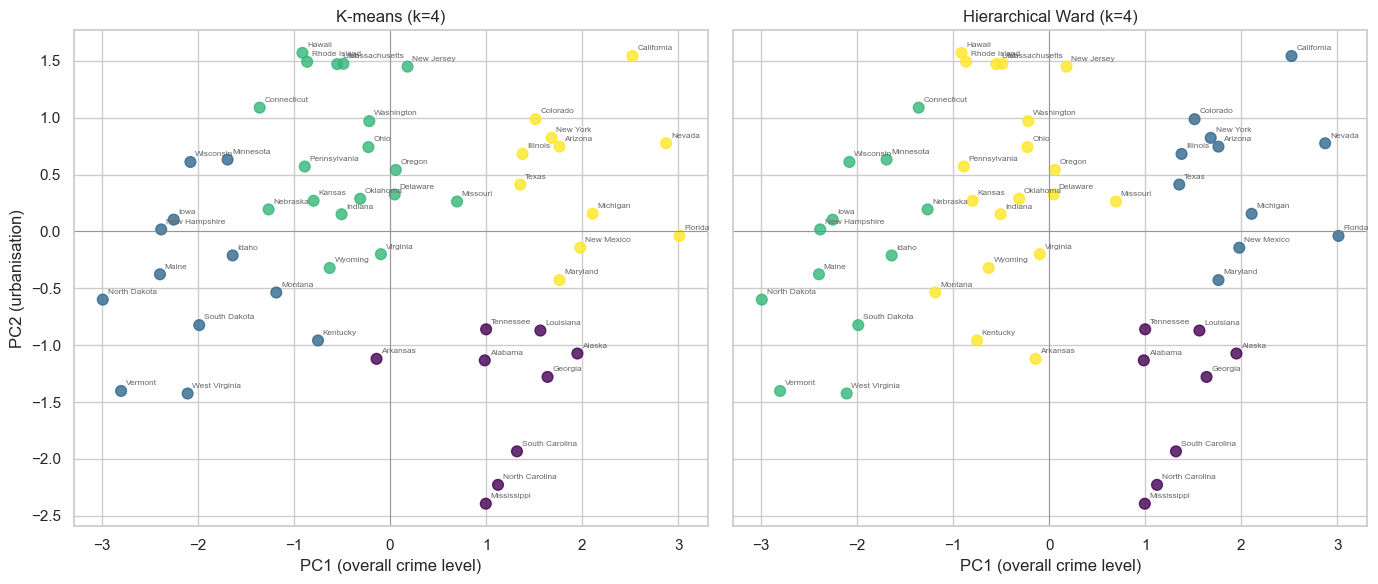

In [34]:
def plot_cluster_comparison(components_df, label_sets):
    """Plot PC1 vs PC2 coloured by each set of cluster labels."""
    fig, axes = plt.subplots(1, len(label_sets), figsize=(14, 6), sharey=True)

    for ax, (title, labels) in zip(axes, label_sets.items()):
        ax.scatter(components_df['PC1'], components_df['PC2'],
                   c=labels, cmap='viridis', s=60, alpha=0.8)
        for state in components_df.index:
            ax.text(components_df.loc[state, 'PC1'] + 0.05,
                    components_df.loc[state, 'PC2'] + 0.05,
                    state, fontsize=6, color='dimgrey')
        ax.set_title(title)
        ax.set_xlabel('PC1 (overall crime level)')
        ax.axhline(0, color='grey', linewidth=0.5)
        ax.axvline(0, color='grey', linewidth=0.5)

    axes[0].set_ylabel('PC2 (urbanisation)')
    plt.tight_layout()
    plt.show()


plot_cluster_comparison(pca_2d, {
    f'K-means (k={K_CLUSTERS})': results_df['KMeans'],
    f'Hierarchical Ward (k={K_CLUSTERS})': results_df['Hierarchical']
})


### Conclusion
- **Preprocessing:** the four variables were standardised because Assault's scale (std ≈ 83) would otherwise have dominated PCA.
- **Correlation:** Murder, Assault and Rape are strongly correlated (0.56–0.80), while UrbanPop is largely independent of Murder (0.07), pointing to two underlying dimensions.
- **PCA:** PC1 (62.0%) captures overall violent crime and PC2 (24.7%) captures urbanisation. Two components retain 86.8% of the variance, reducing four variables to two with little information lost.
- **Clustering:** k-means (silhouette 0.444) and Ward hierarchical clustering (0.413) both produced four groups and agreed closely, which suggests the structure is genuine rather than an artefact of either algorithm. K-means scored slightly higher, while the dendrogram gave clearer visual justification for the number of clusters.
- **Overall:** US states in 1973 separate mainly by violent crime level, with urbanisation as a secondary and largely independent dimension. High crime is not confined to urban states: several rural southern states show high crime with low urbanisation.
